# Real image vs generated image: detection with a CNN and transfer learning

ESILV project, “Neural Networks & Deep Learning”.

**Team**: Thierno DIALLO (team head), Joe VASEEKARAN, Lisandru ZUCCARELLI, Noé PAYAN.

**Task**: classify an image as a **real image** (a photo taken by a camera) or a **generated image** (entirely produced by an AI model), whatever the generator.

**Method**: ResNet50 pre-trained on ImageNet, fine-tuned in two phases on the `cartografia/unbiased-tiny-genimage` dataset (debiased GenImage: everything is JPEG quality 96).

**Two experiments, same model**:
- **“all generators”**: training and testing on the 7 generators;
- **“held-out generators”**: training without Midjourney or BigGAN, then testing on these two never-seen generators.

**Training run 2**: compared with the first run, we add a **random blur + JPEG augmentation** on both classes, so that the model can no longer use sharpness as a cue, and **early stopping** in both phases, with more epochs.

The notebook runs as-is on Colab or Kaggle, from top to bottom. Every decision is explained in the project report (`docs/rapport_projet_en.docx`).

## 1. Package installation

On Colab or Kaggle, missing packages are installed with `pip`. Locally, the project is managed with **uv**: install with `uv add`, so that `pyproject.toml` and `uv.lock` stay up to date.

In [1]:
import importlib.util
import os
import subprocess
import sys

# Imported module name -> package name to install
REQUIRED_PACKAGES = {
    "tensorflow": "tensorflow",
    "kagglehub": "kagglehub",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "pandas": "pandas",
}

# Colab and Kaggle can be recognised by environment variables they set themselves
ON_THE_CLOUD = "COLAB_RELEASE_TAG" in os.environ or "KAGGLE_KERNEL_RUN_TYPE" in os.environ

missing_packages = [package for module, package in REQUIRED_PACKAGES.items() if importlib.util.find_spec(module) is None]

if not missing_packages:
    print("All packages are already installed.")
elif ON_THE_CLOUD:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])
    print("Installed:", missing_packages)
else:
    raise ImportError(
        f"Missing packages: {missing_packages}. Locally, install them with: uv add {' '.join(missing_packages)}"
    )

All packages are already installed.


## 2. Imports

In [2]:
import json
import random
from pathlib import Path

import kagglehub
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | Keras 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 3. Downloads

The dataset comes from Kaggle (`cartografia/unbiased-tiny-genimage`, 2.5 GB, CC BY-NC-SA 4.0 licence). On Kaggle, simply add it to the notebook (“Add Input”); elsewhere, `kagglehub` downloads it.

The ResNet50 ImageNet weights are also downloaded right away, so that every download happens at the start of the notebook.

`SMOKE_TEST = True` runs a miniature version (a few images, 1 epoch, no pre-trained weights) whose only purpose is to check that the notebook runs end to end.

In [3]:
# Quick test mode: True to check that everything runs, False for the real training
SMOKE_TEST = False #os.environ.get("SMOKE_TEST", "0") == "1"

KAGGLE_DATASET = "cartografia/unbiased-tiny-genimage"
KAGGLE_INPUT_DIR = Path("/kaggle/input/unbiased-tiny-genimage")
REAL_FOLDER = "Nature"  # folder of the real images in the dataset

# No pre-trained weights in test mode, to avoid a useless download
WEIGHTS = None if SMOKE_TEST else "imagenet"


def find_dataset_root(start_dir):
    """Finds the dataset folder that contains the real-image subfolder.

    Depending on the platform, the dataset may sit one or two levels below
    the download folder.

    Args:
        start_dir: folder to start searching from.

    Returns:
        The path (Path) of the folder that contains `Nature/` and the generator folders.
    """
    start_dir = Path(start_dir)
    for folder, subfolders, _ in os.walk(start_dir):
        if REAL_FOLDER in subfolders:
            return Path(folder)
    raise FileNotFoundError(f"No '{REAL_FOLDER}' folder found under {start_dir}")


# Priority: path set by an environment variable, then dataset attached on Kaggle, then download
if os.environ.get("GENIMAGE_DIR"):
    download_dir = Path(os.environ["GENIMAGE_DIR"])
elif KAGGLE_INPUT_DIR.exists():
    download_dir = KAGGLE_INPUT_DIR
else:
    download_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))

DATA_DIR = find_dataset_root(download_dir)
print("Dataset:", DATA_DIR)
print("Folders:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

# Downloads and caches the ResNet50 ImageNet weights (about 95 MB)
if WEIGHTS == "imagenet":
    keras.applications.ResNet50(include_top=False, weights="imagenet")
    print("ResNet50 ImageNet weights cached.")

Dataset: /kaggle/input/datasets/cartografia/unbiased-tiny-genimage
Folders: ['ADM', 'BigGAN', 'Midjourney', 'Nature', 'VQDM', 'glide', 'stable_diffusion_v_1_5', 'wukong']
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 ImageNet weights cached.


## 4. Configuration, balanced subsets and split

Both experiments are **balanced 50/50**: we keep every real image and draw the same number of images from each generator, so that there are as many generated images as real ones.

| | “all generators” | “held-out generators” |
|---|---|---|
| Generators in training | all 7 | ADM, GLIDE, VQDM, SD 1.5, Wukong |
| Generated images per generator | ~833 | ~1,165 |

Each subset is split **70 / 15 / 15** (train / validation / test), stratified by class and by generator.

In [4]:
SEED = 42

GENERATORS = ["ADM", "BigGAN", "Midjourney", "VQDM", "glide", "stable_diffusion_v_1_5", "wukong"]
HELD_OUT_GENERATORS = ["Midjourney", "BigGAN"]  # never seen during training in experiment 2

CROP_SIZE = 128  # BigGAN's size, the smallest in the dataset: cropping is possible everywhere without resizing
INPUT_SIZE = 224  # usual ResNet50 input size
BATCH_SIZE = 8 if SMOKE_TEST else 64
# Maximum numbers of epochs: early stopping stops sooner if validation stops improving
EPOCHS_PHASE1 = 1 if SMOKE_TEST else 10
EPOCHS_PHASE2 = 1 if SMOKE_TEST else 30
LR_PHASE1 = 1e-3
LR_PHASE2 = 1e-5
DROPOUT = 0.3
PATIENCE = 4  # early stopping: epochs without validation-loss improvement before stopping
THRESHOLD = 0.5  # probability above which an image is classified “generated”
MAX_IMAGES_PER_FOLDER = 60 if SMOKE_TEST else None

# Augmentation in training only, applied to both classes (see section 5)
AUGMENT = True
BLUR_PROBABILITY = 0.5
BLUR_SIGMA_MAX = 2.0  # blur σ drawn at random between 0 and this value, in pixels
JPEG_PROBABILITY = 0.5
JPEG_QUALITY_MIN = 50  # JPEG quality drawn at random between these two bounds
JPEG_QUALITY_MAX = 100

# Keeps decoded images (train + validation) in memory so they are not re-read at every epoch.
# About 15 GB of RAM in total: fine on Kaggle (29 GB), set to False on free Colab (~12 GB).
CACHE_DECODED_IMAGES = True

EVAL_GRID = 3  # multi-crop evaluation: EVAL_GRID × EVAL_GRID grid of crops per image (see section 9)

RUN_NAME = "train2"  # prefix of the saved files, to avoid confusion with training run 1
# Quick test mode writes to a separate folder: its miniature models can never be reloaded by mistake
OUTPUT_DIR = Path(os.environ.get("OUTPUT_DIR", "outputs_smoke" if SMOKE_TEST else "outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REUSE_SAVED_MODELS = True  # reloads an already trained model instead of retraining it


def set_seeds(seed):
    """Sets every random seed (Python, NumPy, TensorFlow) for reproducibility.

    Args:
        seed: the seed to use.
    """
    random.seed(seed)
    np.random.seed(seed)
    keras.utils.set_random_seed(seed)


def list_images(data_dir, max_per_folder=None):
    """Lists every image of the dataset.

    Args:
        data_dir: root folder of the dataset (contains `Nature/` and one folder per generator).
        max_per_folder: maximum number of images kept per folder (None = all).

    Returns:
        DataFrame with one row per image: `path`, `source` (folder name) and
        `label` (0 = real image, 1 = generated image).
    """
    extensions = {".jpg", ".jpeg", ".png"}
    rows = []
    for source in [REAL_FOLDER, *GENERATORS]:
        paths = sorted(p for p in (data_dir / source).iterdir() if p.suffix.lower() in extensions)
        if max_per_folder is not None:
            paths = paths[:max_per_folder]
        label = 0 if source == REAL_FOLDER else 1
        rows += [{"path": str(p), "source": source, "label": label} for p in paths]
    return pd.DataFrame(rows)


def build_balanced_subset(inventory, generators, seed):
    """Builds a subset balanced 50/50 between real and generated images.

    Every real image is kept. The same number of images is drawn at random
    from each generator, so that the total of generated images is roughly
    equal to the number of real images.

    Args:
        inventory: DataFrame returned by `list_images`.
        generators: generators to include.
        seed: sampling seed.

    Returns:
        The shuffled subset (DataFrame).
    """
    real = inventory[inventory["source"] == REAL_FOLDER]
    per_generator = len(real) // len(generators)
    generated = [
        inventory[inventory["source"] == g].sample(n=per_generator, random_state=seed)
        for g in generators
    ]
    return pd.concat([real, *generated]).sample(frac=1, random_state=seed).reset_index(drop=True)


def split_train_val_test(subset, seed):
    """Splits a subset into train / validation / test (70 / 15 / 15).

    The split is stratified on `source`, hence both by class and by generator.

    Args:
        subset: DataFrame to split.
        seed: split seed.

    Returns:
        Dictionary {"train": ..., "val": ..., "test": ...} of DataFrames.
    """
    train, rest = train_test_split(subset, test_size=0.30, stratify=subset["source"], random_state=seed)
    val, test = train_test_split(rest, test_size=0.50, stratify=rest["source"], random_state=seed)
    return {"train": train.reset_index(drop=True), "val": val.reset_index(drop=True), "test": test.reset_index(drop=True)}


def count_table(splits):
    """Counts images per source and per split, for checking.

    Args:
        splits: dictionary returned by `split_train_val_test`.

    Returns:
        DataFrame (sources as rows, splits as columns, with a total).
    """
    table = pd.DataFrame({name: df["source"].value_counts() for name, df in splits.items()}).fillna(0).astype(int)
    table.loc["TOTAL"] = table.sum()
    return table


set_seeds(SEED)
inventory = list_images(DATA_DIR, MAX_IMAGES_PER_FOLDER)
print("Images found per folder:")
print(inventory["source"].value_counts().to_string())

# Experiment 1: the 7 generators
splits_all = split_train_val_test(build_balanced_subset(inventory, GENERATORS, SEED), SEED)

# Experiment 2: without Midjourney or BigGAN
TRAIN_GENERATORS_HELD_OUT = [g for g in GENERATORS if g not in HELD_OUT_GENERATORS]
splits_held_out = split_train_val_test(build_balanced_subset(inventory, TRAIN_GENERATORS_HELD_OUT, SEED), SEED)

# Test on never-seen generators: all their images, against the real images of experiment 2's test set
held_out_test = pd.concat([
    inventory[inventory["source"].isin(HELD_OUT_GENERATORS)],
    splits_held_out["test"][splits_held_out["test"]["label"] == 0],
]).reset_index(drop=True)

print("\n“All generators” experiment:")
print(count_table(splits_all))
print("\n“Held-out generators” experiment:")
print(count_table(splits_held_out))
print("\nTest on held-out generators:")
print(held_out_test["source"].value_counts().to_string())

Images found per folder:
source
Nature                    5828
ADM                       2500
BigGAN                    2500
Midjourney                2500
VQDM                      2500
glide                     2500
stable_diffusion_v_1_5    2500
wukong                    2500

“All generators” experiment:
                        train   val  test
source                                   
ADM                       583   124   125
BigGAN                    583   125   124
Midjourney                582   125   125
Nature                   4080   874   874
VQDM                      582   125   125
glide                     582   125   125
stable_diffusion_v_1_5    582   125   125
wukong                    582   125   125
TOTAL                    8156  1748  1748

“Held-out generators” experiment:
                        train   val  test
source                                   
ADM                       815   175   175
Nature                   4080   874   874
VQDM                     

## 5. Preprocessing

The GenImage pitfall: each generator has its own size (128 to 1024 px) whereas real images are ~500 px. If each image is resized by a different factor depending on its class, the model learns these resizing traces instead of learning “real vs generated”.

The pipeline is therefore **identical for every image**:
1. decoding into RGB pixels (metadata is discarded);
2. **128 × 128 px crop at native resolution**, random in training and centred in validation and test;
3. **upscaling to 224 × 224 px**, the same ×1.75 factor for every image;
4. `resnet50.preprocess_input` normalisation.

**Augmentation (training only, new in training run 2)**: before the crop, at native resolution, each training image, **real or generated**, randomly receives:
- a **Gaussian blur** (probability 0.5, σ between 0 and 2);
- a **JPEG recompression** (probability 0.5, quality between 50 and 100).

The first run had learned “sharp = real”: about 40% of the blurred or recompressed real photos were classified “generated”. By degrading both classes in the same way, sharpness no longer separates the classes, and the model must find more robust cues. Validation and test remain without augmentation.

**Speed optimisations (no effect on the result)**: the CPU was the bottleneck, and the GPU was waiting.
- Decoded images are **kept in memory** after the first epoch (`CACHE_DECODED_IMAGES`, ~15 GB of RAM: set it to `False` on free Colab).
- Blur and JPEG are no longer applied to the whole image, but to a **window around the crop**, aligned on the JPEG grid with a 32 px margin. The pixels of the resulting crop are **identical** to those obtained by degrading the whole image (checked pixel by pixel on 168 cases), at about a quarter of the cost on a Midjourney image.

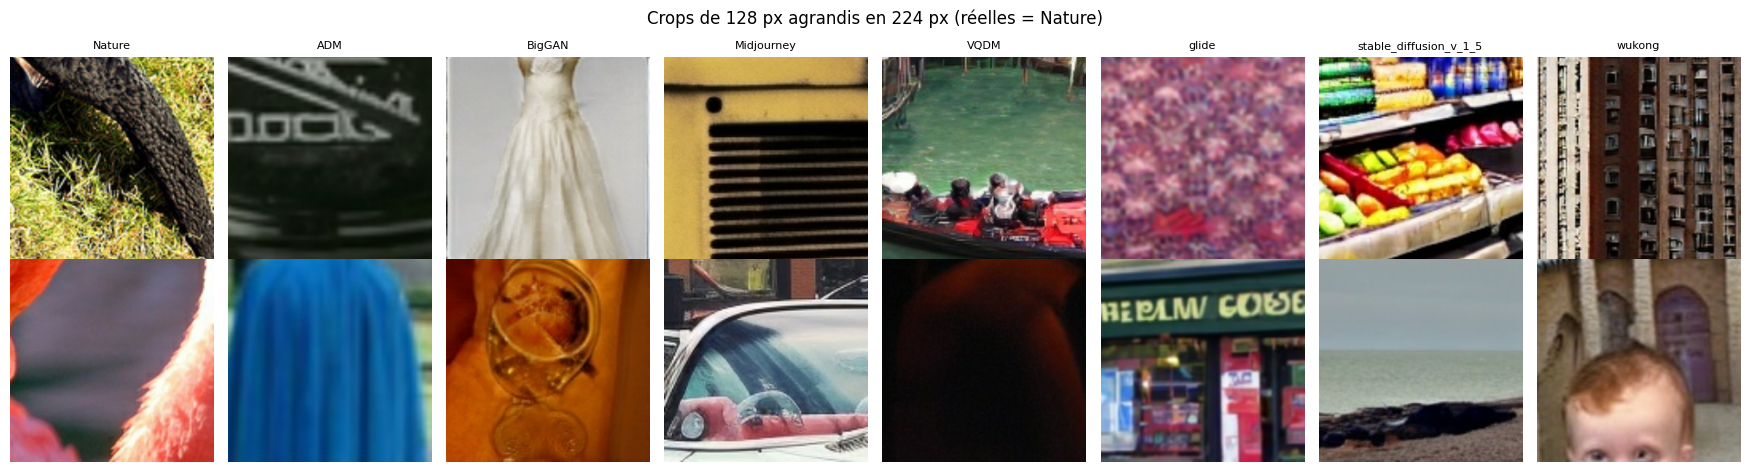

In [5]:
AUTOTUNE = tf.data.AUTOTUNE


def decode_image(path):
    """Reads an image file and decodes it into an RGB uint8 tensor of shape (height, width, 3).

    Args:
        path: file path (string tensor).

    Returns:
        uint8 tensor of the image.
    """
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])  # decode_image does not know the size in advance
    return image


def crop_and_resize(image, training):
    """Cuts a CROP_SIZE px square at native resolution, then upscales it to INPUT_SIZE px.

    Args:
        image: uint8 tensor (height, width, 3).
        training: True for a random crop, False for a centred crop.

    Returns:
        float32 tensor (INPUT_SIZE, INPUT_SIZE, 3), values between 0 and 255.
    """
    if training:
        image = tf.image.random_crop(image, size=[CROP_SIZE, CROP_SIZE, 3])
    else:
        image = tf.image.resize_with_crop_or_pad(image, CROP_SIZE, CROP_SIZE)  # centred crop
    image = tf.cast(image, tf.float32)
    # Same upscaling factor (×1.75) for every image, whatever its class
    return tf.image.resize(image, [INPUT_SIZE, INPUT_SIZE], method="bilinear")


def gaussian_blur(image, sigma, kernel_size=9):
    """Applies a Gaussian blur.

    Args:
        image: uint8 tensor (height, width, 3).
        sigma: standard deviation of the Gaussian kernel in pixels (number or scalar tensor).
        kernel_size: kernel size (odd), large enough for σ <= kernel_size / 3.

    Returns:
        Blurred uint8 tensor of the same size.
    """
    sigma = tf.maximum(tf.cast(sigma, tf.float32), 1e-3)  # avoids a division by zero when σ ≈ 0
    axis = tf.range(kernel_size, dtype=tf.float32) - (kernel_size - 1) / 2
    kernel_1d = tf.exp(-(axis**2) / (2 * sigma**2))
    kernel_2d = tf.tensordot(kernel_1d, kernel_1d, axes=0)
    kernel_2d /= tf.reduce_sum(kernel_2d)
    # Same kernel applied separately to each of the 3 channels (depthwise convolution)
    kernel = tf.tile(kernel_2d[:, :, None, None], [1, 1, 3, 1])
    blurred = tf.nn.depthwise_conv2d(tf.cast(image, tf.float32)[None], kernel, strides=[1, 1, 1, 1], padding="SAME")[0]
    return tf.cast(tf.clip_by_value(tf.round(blurred), 0, 255), tf.uint8)


# Optimisation: we do not degrade the whole image, only a window around the crop.
# Blur only depends on neighbouring pixels (4 px radius) and JPEG works in blocks
# of 16 × 16 px (aligned on the image corner). With a window aligned on this grid
# and a 32 px margin, the crop pixels are exactly the same as if the whole image
# had been degraded (checked pixel by pixel), at a much lower cost.
JPEG_BLOCK = 16
WINDOW_MARGIN = 32


def degrade(image, apply_blur, sigma, apply_jpeg, quality):
    """Applies (or not) a blur, then (or not) a JPEG recompression, with given parameters.

    Args:
        image: uint8 tensor (height, width, 3).
        apply_blur: boolean (tensor), whether to apply the blur.
        sigma: blur σ in pixels.
        apply_jpeg: boolean (tensor), whether to apply the recompression.
        quality: JPEG quality (integer).

    Returns:
        uint8 tensor of the same size.
    """
    image = tf.cond(apply_blur, lambda: gaussian_blur(image, sigma), lambda: image)
    image = tf.cond(apply_jpeg, lambda: tf.image.adjust_jpeg_quality(image, quality), lambda: image)
    image.set_shape([None, None, 3])  # tf.cond sometimes loses the static shape
    return image


def degraded_crop(image, top, left, apply_blur, sigma, apply_jpeg, quality):
    """CROP_SIZE px crop at position (top, left), degraded as if the whole image had been.

    We cut a window aligned on the image's JPEG grid, with a margin of
    WINDOW_MARGIN px around the crop, degrade it, then extract the crop.

    Args:
        image: uint8 tensor (height, width, 3), at native resolution.
        top, left: top-left corner of the crop in the image.
        apply_blur, sigma, apply_jpeg, quality: parameters of `degrade`.

    Returns:
        uint8 tensor (CROP_SIZE, CROP_SIZE, 3).
    """
    height, width = tf.shape(image)[0], tf.shape(image)[1]
    # Window start: margin removed, then rounded down to the JPEG grid
    window_top = tf.maximum(0, (top - WINDOW_MARGIN) // JPEG_BLOCK * JPEG_BLOCK)
    window_left = tf.maximum(0, (left - WINDOW_MARGIN) // JPEG_BLOCK * JPEG_BLOCK)
    # Window end: margin added, without going past the image
    window_bottom = tf.minimum(height, top + CROP_SIZE + WINDOW_MARGIN)
    window_right = tf.minimum(width, left + CROP_SIZE + WINDOW_MARGIN)
    window = image[window_top:window_bottom, window_left:window_right]
    window = degrade(window, apply_blur, sigma, apply_jpeg, quality)
    return tf.image.crop_to_bounding_box(window, top - window_top, left - window_left, CROP_SIZE, CROP_SIZE)


def random_training_crop(image):
    """Training crop: random position and, if AUGMENT, random blur and JPEG.

    The degradations are applied in the same way to real and generated images,
    so that sharpness or compression can no longer separate the classes.

    Args:
        image: uint8 tensor (height, width, 3), at native resolution.

    Returns:
        uint8 tensor (CROP_SIZE, CROP_SIZE, 3).
    """
    height, width = tf.shape(image)[0], tf.shape(image)[1]
    top = tf.random.uniform([], 0, height - CROP_SIZE + 1, dtype=tf.int32)
    left = tf.random.uniform([], 0, width - CROP_SIZE + 1, dtype=tf.int32)
    if not AUGMENT:
        return tf.image.crop_to_bounding_box(image, top, left, CROP_SIZE, CROP_SIZE)
    apply_blur = tf.random.uniform([]) < BLUR_PROBABILITY
    sigma = tf.random.uniform([], 0.0, BLUR_SIGMA_MAX)
    apply_jpeg = tf.random.uniform([]) < JPEG_PROBABILITY
    quality = tf.random.uniform([], JPEG_QUALITY_MIN, JPEG_QUALITY_MAX + 1, dtype=tf.int32)
    return degraded_crop(image, top, left, apply_blur, sigma, apply_jpeg, quality)


def make_dataset(df, training, perturbation=None, batch_size=None, cache=False):
    """Builds the tf.data pipeline of a DataFrame of images.

    Args:
        df: DataFrame with the `path` and `label` columns.
        training: True to shuffle and take random crops (augmented if AUGMENT).
        perturbation: optional function applied to the decoded uint8 image
            (used by the perturbation test).
        batch_size: batch size (BATCH_SIZE by default).
        cache: True to keep decoded images in memory after the first epoch
            (they are no longer re-read or re-decoded afterwards).

    Returns:
        tf.data.Dataset of (preprocessed image, label) pairs.
    """
    dataset = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values.astype("float32")))
    # Reading and decoding: the only step that does not change from one epoch to the next
    dataset = dataset.map(lambda path, label: (decode_image(path), label), num_parallel_calls=AUTOTUNE)
    if cache:
        dataset = dataset.cache()
    if training:
        dataset = dataset.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)

    def process(image, label):
        if perturbation is not None:
            image = perturbation(image)
        if training:
            crop = tf.cast(random_training_crop(image), tf.float32)
            image = tf.image.resize(crop, [INPUT_SIZE, INPUT_SIZE], method="bilinear")  # same ×1.75 as crop_and_resize
        else:
            image = crop_and_resize(image, training=False)
        return keras.applications.resnet50.preprocess_input(image), label

    return dataset.map(process, num_parallel_calls=AUTOTUNE).batch(batch_size or BATCH_SIZE).prefetch(AUTOTUNE)


def load_display_image(path):
    """Loads an image as the model sees it at evaluation (upscaled centred crop), for display.

    Args:
        path: image file path.

    Returns:
        uint8 NumPy array (INPUT_SIZE, INPUT_SIZE, 3).
    """
    image = crop_and_resize(decode_image(tf.constant(path)), training=False)
    return tf.cast(image, tf.uint8).numpy()


def show_examples(inventory, per_source=2):
    """Shows a few images from each folder, as the model sees them.

    Args:
        inventory: DataFrame returned by `list_images`.
        per_source: number of images per folder.
    """
    sources = [REAL_FOLDER, *GENERATORS]
    fig, axes = plt.subplots(per_source, len(sources), figsize=(2.2 * len(sources), 2.4 * per_source))
    for col, source in enumerate(sources):
        sample = inventory[inventory["source"] == source].sample(per_source, random_state=SEED)
        for row, path in enumerate(sample["path"]):
            ax = axes[row, col]
            ax.imshow(load_display_image(path))
            ax.set_title(source if row == 0 else "", fontsize=8)
            ax.axis("off")
    fig.suptitle("128 px crops upscaled to 224 px (real = Nature)")
    plt.tight_layout()
    plt.show()


show_examples(inventory)

## 6. Model construction

- **Backbone**: ResNet50 pre-trained on ImageNet, without its classification head.
- **Head**: GlobalAveragePooling → Dropout(0.3) → 1 sigmoid neuron (probability that the image is generated).
- **Phase 1**: backbone frozen, only the head learns (lr 1e-3, at most 10 epochs).
- **Phase 2**: the last block `conv5` is unfrozen (lr 1e-5, at most 30 epochs).
- **Early stopping in both phases**: training stops when the validation loss has not improved for 4 epochs, and the weights of the best epoch are restored. This is what prevents overfitting despite the higher number of epochs.

BatchNorm layers stay in inference mode (`training=False`), as Keras recommends for fine-tuning.

In [6]:
# Mixed precision: faster on GPU, useless on CPU
if tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")
print("Precision policy:", keras.mixed_precision.global_policy().name)


def build_model(weights):
    """Builds ResNet50 + binary classification head, with the backbone frozen.

    Args:
        weights: "imagenet" for pre-trained weights, None for random weights.

    Returns:
        The complete Keras model.
    """
    backbone = keras.applications.ResNet50(include_top=False, weights=weights, input_shape=(INPUT_SIZE, INPUT_SIZE, 3))
    backbone.trainable = False

    inputs = keras.Input(shape=(INPUT_SIZE, INPUT_SIZE, 3))
    x = backbone(inputs, training=False)  # BatchNorm in inference mode, even after unfreezing
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(DROPOUT)(x)
    # float32 output for numerical stability under mixed precision
    outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="resnet50_real_vs_generated")


def unfreeze_last_block(model):
    """Unfreezes the last ResNet50 block (conv5), keeping the BatchNorm layers frozen.

    Args:
        model: model returned by `build_model`.
    """
    backbone = model.get_layer("resnet50")
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, layers.BatchNormalization)


def compile_model(model, learning_rate):
    """Compiles the model with Adam, binary cross-entropy, accuracy and AUC.

    Args:
        model: the Keras model.
        learning_rate: learning rate.
    """
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )


def early_stopping():
    """Creates the early-stopping callback used in both phases.

    It monitors the validation loss, stops after PATIENCE epochs without
    improvement and restores the weights of the best epoch.

    Returns:
        The Keras callback.
    """
    return keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
    )


def train_or_load(name, splits):
    """Trains the model of an experiment in two phases, or reloads it if it already exists.

    Both phases use early stopping. The model and the training history are
    saved in OUTPUT_DIR, so that they can be re-evaluated without retraining.

    Args:
        name: experiment name (used as file name, prefixed with RUN_NAME).
        splits: dictionary returned by `split_train_val_test`.

    Returns:
        (model, history) pair; the history is a dict metric -> list per epoch.
    """
    model_path = OUTPUT_DIR / f"{RUN_NAME}_{name}.keras"
    history_path = OUTPUT_DIR / f"{RUN_NAME}_{name}_history.json"
    if REUSE_SAVED_MODELS and model_path.exists():
        print(f"Model {name} reloaded from {model_path}")
        history = json.loads(history_path.read_text()) if history_path.exists() else {}
        return keras.models.load_model(model_path), history

    set_seeds(SEED)
    train_ds = make_dataset(splits["train"], training=True, cache=CACHE_DECODED_IMAGES)
    val_ds = make_dataset(splits["val"], training=False, cache=CACHE_DECODED_IMAGES)
    model = build_model(WEIGHTS)

    print(f"--- {name}: phase 1 (frozen backbone) ---")
    compile_model(model, LR_PHASE1)
    phase1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE1, callbacks=[early_stopping()])

    print(f"--- {name}: phase 2 (conv5 unfrozen) ---")
    unfreeze_last_block(model)
    compile_model(model, LR_PHASE2)  # recompiling is mandatory after changing `trainable`
    phase2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE2, callbacks=[early_stopping()])

    # History of both phases concatenated
    history = {k: [float(v) for v in phase1.history[k] + phase2.history.get(k, [])] for k in phase1.history}
    history["phase2_start"] = len(phase1.history["loss"])
    model.save(model_path)
    history_path.write_text(json.dumps(history))
    return model, history


def plot_history(history, title):
    """Plots the loss and the AUC (training and validation) over the epochs.

    Args:
        history: history returned by `train_or_load`.
        title: chart title.
    """
    if not history:
        print("No history available.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, metric in zip(axes, ["loss", "auc"]):
        ax.plot(history[metric], label="train")
        ax.plot(history[f"val_{metric}"], label="validation")
        ax.axvline(history["phase2_start"] - 0.5, color="grey", linestyle="--", label="phase 2 start")
        ax.set_xlabel("epoch")
        ax.set_title(metric)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


build_model(WEIGHTS).summary(show_trainable=True)

Precision policy: mixed_float16


Model: "resnet50_real_vs_generated"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_2 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 1)             │      2,049 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 7. “All generators” experiment: training

Training on a balanced mix of the 7 generators. Question: what score do we get when every generator is known?

--- tous_generateurs: phase 1 (frozen backbone) ---
Epoch 1/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 292s 863ms/step - accuracy: 0.7571 - auc: 0.8380 - loss: 0.5075 - val_accuracy: 0.8318 - val_auc: 0.9399 - val_loss: 0.3798
Epoch 2/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 464ms/step - accuracy: 0.8127 - auc: 0.8878 - loss: 0.4262 - val_accuracy: 0.8719 - val_auc: 0.9527 - val_loss: 0.2934
Epoch 3/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 466ms/step - accuracy: 0.8221 - auc: 0.9023 - loss: 0.3972 - val_accuracy: 0.8884 - val_auc: 0.9598 - val_loss: 0.2622
Epoch 4/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 59s 463ms/step - accuracy: 0.8276 - auc: 0.9067 - loss: 0.3893 - val_accuracy: 0.8862 - val_auc: 0.9627 - val_loss: 0.2586
Epoch 5/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 59s 463ms/step - accuracy: 0.8317 - auc: 0.9100 - loss: 0.3823 - val_accuracy: 0.8701 - val_auc: 0.9633 - val_loss: 0.2922
Epoch 6/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 59s 457ms/step - accuracy: 0.8293 - auc: 0.9122 - loss: 0.3775 - val_accuracy: 0.8890 - val_

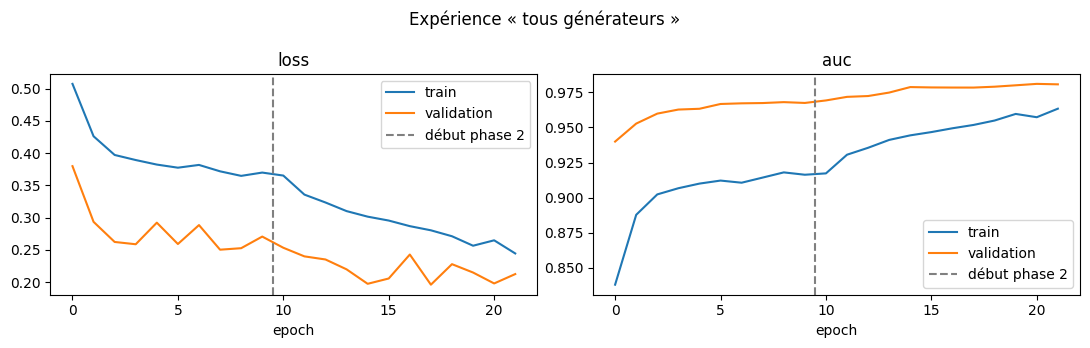

In [7]:
# The file name keeps its original (French) key so that the saved train2 models are reloaded
model_all, history_all = train_or_load("tous_generateurs", splits_all)
plot_history(history_all, "“All generators” experiment")

## 8. “Held-out generators” experiment: training

Same model, trained **without Midjourney or BigGAN**. Question: does the model recognise images coming from generators it has never seen?

--- generateurs_mis_de_cote: phase 1 (frozen backbone) ---
Epoch 1/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 191s 748ms/step - accuracy: 0.7580 - auc: 0.8381 - loss: 0.5085 - val_accuracy: 0.8610 - val_auc: 0.9350 - val_loss: 0.3343
Epoch 2/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 467ms/step - accuracy: 0.8146 - auc: 0.8931 - loss: 0.4172 - val_accuracy: 0.8810 - val_auc: 0.9522 - val_loss: 0.2884
Epoch 3/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 468ms/step - accuracy: 0.8298 - auc: 0.9074 - loss: 0.3877 - val_accuracy: 0.8907 - val_auc: 0.9603 - val_loss: 0.2721
Epoch 4/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 471ms/step - accuracy: 0.8393 - auc: 0.9130 - loss: 0.3770 - val_accuracy: 0.8719 - val_auc: 0.9628 - val_loss: 0.3001
Epoch 5/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 469ms/step - accuracy: 0.8357 - auc: 0.9138 - loss: 0.3751 - val_accuracy: 0.8930 - val_auc: 0.9635 - val_loss: 0.2671
Epoch 6/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 60s 466ms/step - accuracy: 0.8357 - auc: 0.9141 - loss: 0.3739 - val_accuracy: 0.9079

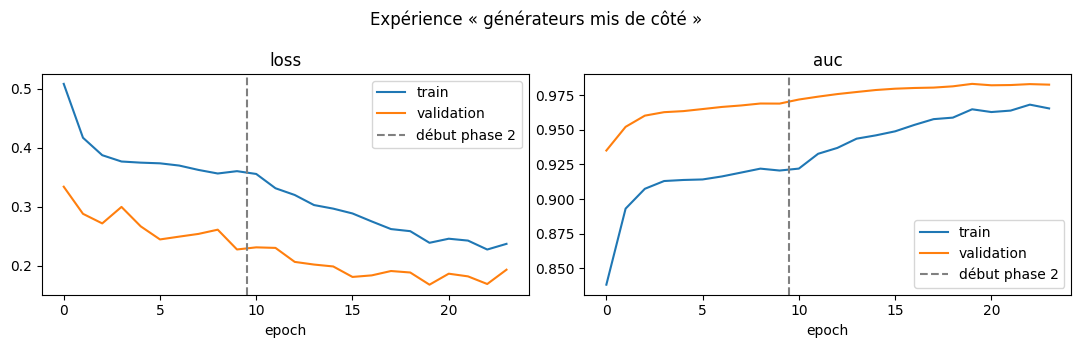

In [8]:
# The file name keeps its original (French) key so that the saved train2 models are reloaded
model_held_out, history_held_out = train_or_load("generateurs_mis_de_cote", splits_held_out)
plot_history(history_held_out, "“Held-out generators” experiment")

## 9. Evaluation and comparison table

Metrics: accuracy, F1, ROC AUC, confusion matrix, and **accuracy per source** (per generator and for the real images). Decision threshold: 0.5.

**Two ways of evaluating, side by side**:
- **1 centred crop**: as in training run 1, for comparison.
- **3 × 3 grid of crops**: each image is cut into 9 evenly spread 128 px crops, still at native resolution, and the final prediction is the **mean of the 9 probabilities**. A single 128 px crop covers only 1.6% of a Midjourney image (1024 px) and may land on an empty area; the grid covers 14%. The procedure is the same for every image, real or generated, so it does not reintroduce any size bias. For BigGAN (128 px), the 9 crops are identical.

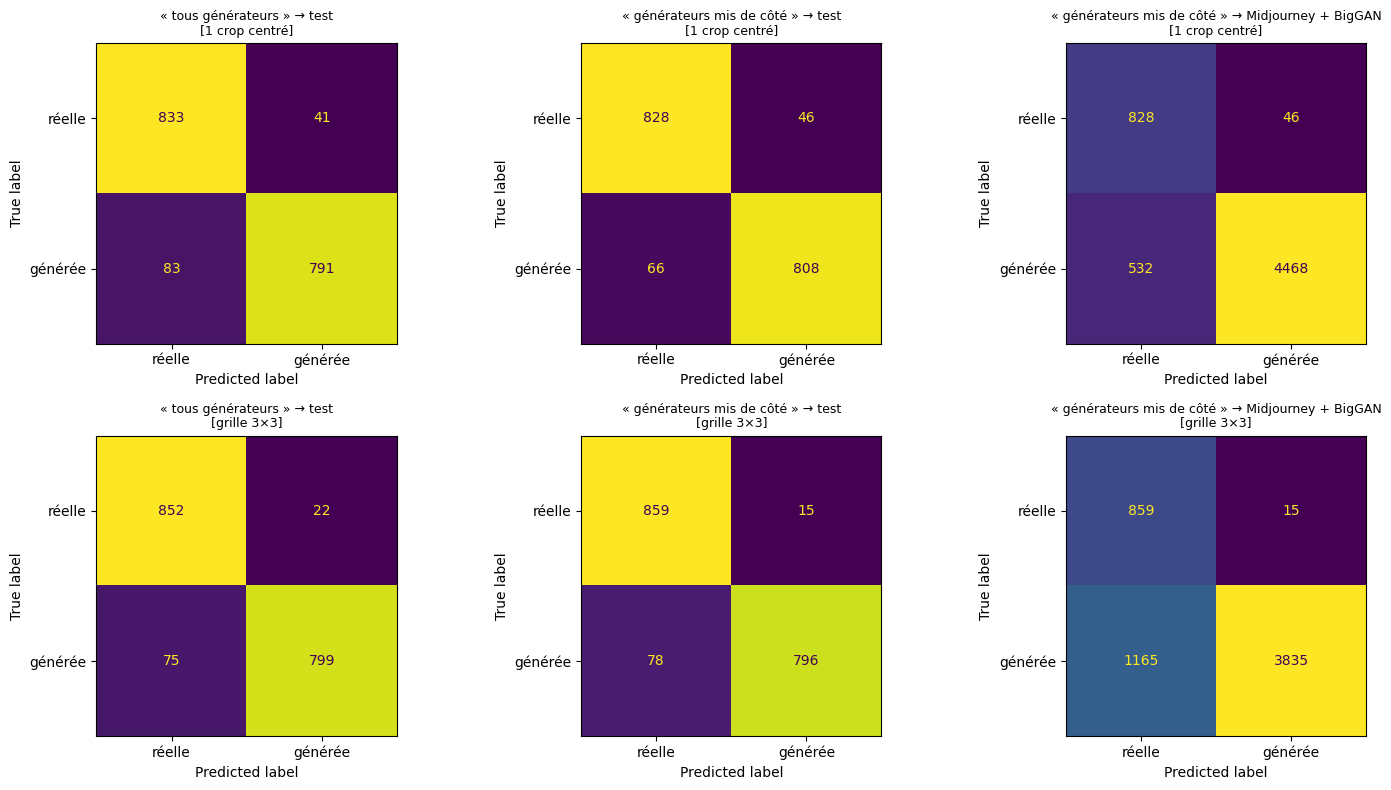

Comparison table (1 centred crop vs grid of crops):


1 centred crop           \
                                                         images accuracy   
evaluation                                                                 
“all generators” → test                                    1748    0.929   
“held-out generators” → test                               1748    0.936   
“held-out generators” → Midjourney + BigGAN                5874    0.902   

                                                                  3×3 grid  \
                                                      f1    auc     images   
evaluation                                                                   
“all generators” → test                            0.927  0.981       1748   
“held-out generators” → test                       0.935  0.984       1748   
“held-out generators” → Midjourney + BigGAN        0.939  0.980       5874   

                                                                          
                                                  accuracy     f1    auc  
evaluation                                                                
“all generators” → test                              0.945  0.943  0.987  
“held-out generators” → test                         0.947  0.945  0.991  
“held-out generators” → Midjourney + BigGAN          0.799  0.867  0.982

Accuracy per source [1 centred crop] (detection rate for the generators):


,“all generators” → test,“held-out generators” → test,“held-out generators” → Midjourney + BigGAN
ADM,0.904,0.926,NaN
BigGAN,0.952,NaN,0.938
Midjourney,0.880,NaN,0.849
Nature,0.953,0.947,0.947
VQDM,0.864,0.874,NaN
glide,0.912,0.926,NaN
stable_diffusion_v_1_5,0.936,0.949,NaN
wukong,0.888,0.948,NaN


Accuracy per source [3×3 grid] (detection rate for the generators):


,“all generators” → test,“held-out generators” → test,“held-out generators” → Midjourney + BigGAN
ADM,0.904,0.874,NaN
BigGAN,0.952,NaN,0.938
Midjourney,0.896,NaN,0.596
Nature,0.975,0.983,0.983
VQDM,0.880,0.886,NaN
glide,0.896,0.886,NaN
stable_diffusion_v_1_5,0.952,0.949,NaN
wukong,0.920,0.960,NaN


In [9]:
def predict_probabilities(model, df, perturbation=None):
    """Computes the “generated image” probability for each image of a DataFrame.

    Args:
        model: trained model.
        df: DataFrame with `path` and `label`.
        perturbation: optional perturbation (see `make_dataset`).

    Returns:
        NumPy array of probabilities, in the order of `df`.
    """
    dataset = make_dataset(df, training=False, perturbation=perturbation)
    return model.predict(dataset, verbose=0).ravel()


def grid_crops(image, grid):
    """Cuts a grid × grid grid of CROP_SIZE px crops, at native resolution, upscaled to INPUT_SIZE.

    The crops are evenly spread, from the top-left corner to the bottom-right corner.

    Args:
        image: uint8 tensor (height, width, 3).
        grid: number of crops per side.

    Returns:
        float32 tensor (grid * grid, INPUT_SIZE, INPUT_SIZE, 3), values between 0 and 255.
    """
    height, width = tf.shape(image)[0], tf.shape(image)[1]
    crops = []
    for row in range(grid):
        for col in range(grid):
            # Regular offset between 0 and (size - CROP_SIZE); a single centred crop if grid == 1
            top = (height - CROP_SIZE) * row // (grid - 1) if grid > 1 else (height - CROP_SIZE) // 2
            left = (width - CROP_SIZE) * col // (grid - 1) if grid > 1 else (width - CROP_SIZE) // 2
            crops.append(tf.image.crop_to_bounding_box(image, top, left, CROP_SIZE, CROP_SIZE))
    crops = tf.cast(tf.stack(crops), tf.float32)
    # Same ×1.75 upscaling as in training
    return tf.image.resize(crops, [INPUT_SIZE, INPUT_SIZE], method="bilinear")


def predict_probabilities_multicrop(model, df, grid=None):
    """“Generated image” probability per image, averaged over a grid of crops.

    Args:
        model: trained model.
        df: DataFrame with `path`.
        grid: number of crops per side (EVAL_GRID by default).

    Returns:
        NumPy array of mean probabilities, in the order of `df`.
    """
    grid = grid or EVAL_GRID

    def load(path):
        crops = grid_crops(decode_image(path), grid)
        return keras.applications.resnet50.preprocess_input(crops)

    dataset = (
        tf.data.Dataset.from_tensor_slices(df["path"].values)
        .map(load, num_parallel_calls=AUTOTUNE)  # image order is preserved
        .unbatch()  # one element per crop, to build batches of crops
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )
    crop_probabilities = model.predict(dataset, verbose=0).ravel()
    return crop_probabilities.reshape(len(df), grid * grid).mean(axis=1)


def compute_metrics(labels, probabilities):
    """Computes accuracy, F1 and AUC.

    Args:
        labels: true labels (0 = real, 1 = generated).
        probabilities: predicted “generated” probabilities.

    Returns:
        Dictionary of metrics.
    """
    predictions = (probabilities >= THRESHOLD).astype(int)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
        "auc": roc_auc_score(labels, probabilities),
    }


def per_source_accuracy(df, probabilities):
    """Accuracy per source (folder).

    For real images, it is the share classified “real”; for a generator,
    it is the share classified “generated” (its detection rate).

    Args:
        df: DataFrame with `source` and `label`.
        probabilities: predicted “generated” probabilities.

    Returns:
        Series: source -> accuracy.
    """
    correct = (probabilities >= THRESHOLD).astype(int) == df["label"].values
    return pd.Series(correct, index=df["source"].values).groupby(level=0).mean().round(3)


def plot_confusion(labels, probabilities, title, ax):
    """Plots the confusion matrix.

    Args:
        labels: true labels.
        probabilities: predicted “generated” probabilities.
        title: chart title.
        ax: matplotlib axis to draw on.
    """
    matrix = confusion_matrix(labels, (probabilities >= THRESHOLD).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["real", "generated"]).plot(ax=ax, colorbar=False)
    ax.set_title(title, fontsize=9)


# The three evaluations of the protocol
evaluations = {
    "“all generators” → test": (model_all, splits_all["test"]),
    "“held-out generators” → test": (model_held_out, splits_held_out["test"]),
    "“held-out generators” → Midjourney + BigGAN": (model_held_out, held_out_test),
}

MODES = {"1 centred crop": "single", f"{EVAL_GRID}×{EVAL_GRID} grid": "grid"}

results = {mode: [] for mode in MODES}
per_source = {mode: {} for mode in MODES}
probabilities_by_eval = {}  # single crop (also used to pick the Grad-CAM examples)
multicrop_probabilities_by_eval = {}
for name, (model, df) in evaluations.items():
    probabilities_by_eval[name] = predict_probabilities(model, df)
    multicrop_probabilities_by_eval[name] = predict_probabilities_multicrop(model, df)
    for mode, probabilities in zip(MODES, [probabilities_by_eval[name], multicrop_probabilities_by_eval[name]]):
        results[mode].append({"evaluation": name, "images": len(df), **compute_metrics(df["label"], probabilities)})
        per_source[mode][name] = per_source_accuracy(df, probabilities)

# Confusion matrices: one row per evaluation mode
fig, axes = plt.subplots(len(MODES), len(evaluations), figsize=(5 * len(evaluations), 4 * len(MODES)))
for row, (mode, by_eval) in enumerate(zip(MODES, [probabilities_by_eval, multicrop_probabilities_by_eval])):
    for col, (name, (model, df)) in enumerate(evaluations.items()):
        plot_confusion(df["label"], by_eval[name], f"{name}\n[{mode}]", axes[row, col])
plt.tight_layout()
plt.show()

print("Comparison table (1 centred crop vs grid of crops):")
display(pd.concat({mode: pd.DataFrame(rows).set_index("evaluation").round(3) for mode, rows in results.items()}, axis=1))
for mode in MODES:
    print(f"Accuracy per source [{mode}] (detection rate for the generators):")
    display(pd.DataFrame(per_source[mode]))

## 10. Anti-shortcut checks

Two checks to verify that the model has not learned a shortcut (format, compression, size):

1. **Scores per source** (table above): a generator detected at 100% while the others plateau at 60% would be suspicious.
2. **Perturbation test**: we apply **the same** transformation to the test images of **both classes**. If the model relies on sharpness or compression, predictions all flip towards one class. A healthy model sees both rates move only a little.

Since training run 2 learns with blur (σ ≤ 2) and JPEG (quality ≥ 50), succeeding on those degradations does not prove much. We therefore test two groups:
- **within the training range**: JPEG quality 75, blur σ = 1 (the same as in training run 1, for comparison);
- **stronger or never seen**: JPEG quality 40, blur σ = 2.5, and ×0.5 downscaling then upscaling (what social networks do). This group shows whether the model has really become robust.

In [10]:
def jpeg_recompression(image, quality=75):
    """Recompresses an image as JPEG at the given quality.

    Args:
        image: uint8 tensor (height, width, 3).
        quality: JPEG quality (0-100).

    Returns:
        Recompressed uint8 tensor.
    """
    return tf.image.adjust_jpeg_quality(image, quality)


def downscale_upscale(image, factor=0.5):
    """Shrinks the image then brings it back to its original size, like a social network that resizes.

    Args:
        image: uint8 tensor (height, width, 3).
        factor: reduction factor (0.5 = half the size).

    Returns:
        uint8 tensor of the same size, which has lost its finest details.
    """
    size = tf.shape(image)[:2]
    small_size = tf.cast(tf.cast(size, tf.float32) * factor, tf.int32)
    small = tf.image.resize(tf.cast(image, tf.float32), small_size, method="bilinear")
    restored = tf.image.resize(small, size, method="bilinear")
    return tf.cast(tf.clip_by_value(tf.round(restored), 0, 255), tf.uint8)


def perturbation_test(model, df, perturbations):
    """Compares the share of images classified “generated” per class, before and after perturbation.

    Args:
        model: trained model.
        df: test set (DataFrame with `path`, `label`).
        perturbations: dictionary name -> perturbation function.

    Returns:
        DataFrame: one row per condition, the share classified “generated”
        among real images and among generated images.
    """
    rows = []
    for name, perturbation in {"none": None, **perturbations}.items():
        predicted_generated = predict_probabilities(model, df, perturbation) >= THRESHOLD
        rows.append({
            "perturbation": name,
            "real classified “generated”": predicted_generated[df["label"].values == 0].mean(),
            "generated classified “generated”": predicted_generated[df["label"].values == 1].mean(),
        })
    return pd.DataFrame(rows).set_index("perturbation").round(3)


PERTURBATIONS = {
    # Within the training augmentation range (and identical to the training run 1 test)
    "JPEG quality 75": lambda image: jpeg_recompression(image, 75),
    "Gaussian blur σ=1": lambda image: gaussian_blur(image, 1.0),
    # Stronger than the augmentation, or never seen in training
    "JPEG quality 40 (stronger)": lambda image: jpeg_recompression(image, 40),
    "Gaussian blur σ=2.5 (stronger)": lambda image: gaussian_blur(image, 2.5, kernel_size=15),
    "×0.5 downscale then upscale (never seen)": downscale_upscale,
}

for name, (model, df) in list(evaluations.items())[:2]:
    print(f"Perturbation test, {name}:")
    display(perturbation_test(model, df, PERTURBATIONS))

Perturbation test, “all generators” → test:


,real classified “generated”,generated classified “generated”
perturbation,,
none,0.047,0.905
JPEG quality 75,0.154,0.919
Gaussian blur σ=1,0.140,0.911
JPEG quality 40 (stronger),0.130,0.891
Gaussian blur σ=2.5 (stronger),0.468,0.932
×0.5 downscale then upscale (never seen),0.208,0.935


Perturbation test, “held-out generators” → test:


,real classified “generated”,generated classified “generated”
perturbation,,
none,0.053,0.924
JPEG quality 75,0.174,0.945
Gaussian blur σ=1,0.159,0.939
JPEG quality 40 (stronger),0.145,0.900
Gaussian blur σ=2.5 (stronger),0.535,0.950
×0.5 downscale then upscale (never seen),0.223,0.957


## 11. Grad-CAM: where does the model look?

Grad-CAM colours the areas of the image that weighed the most in the decision. We apply it to the model of the “held-out generators” experiment, on the last convolution layer of ResNet50 (`conv5_block3_out`), with 8 examples: 2 real images, 2 correctly classified generated images, 2 errors and 2 images from never-seen generators.

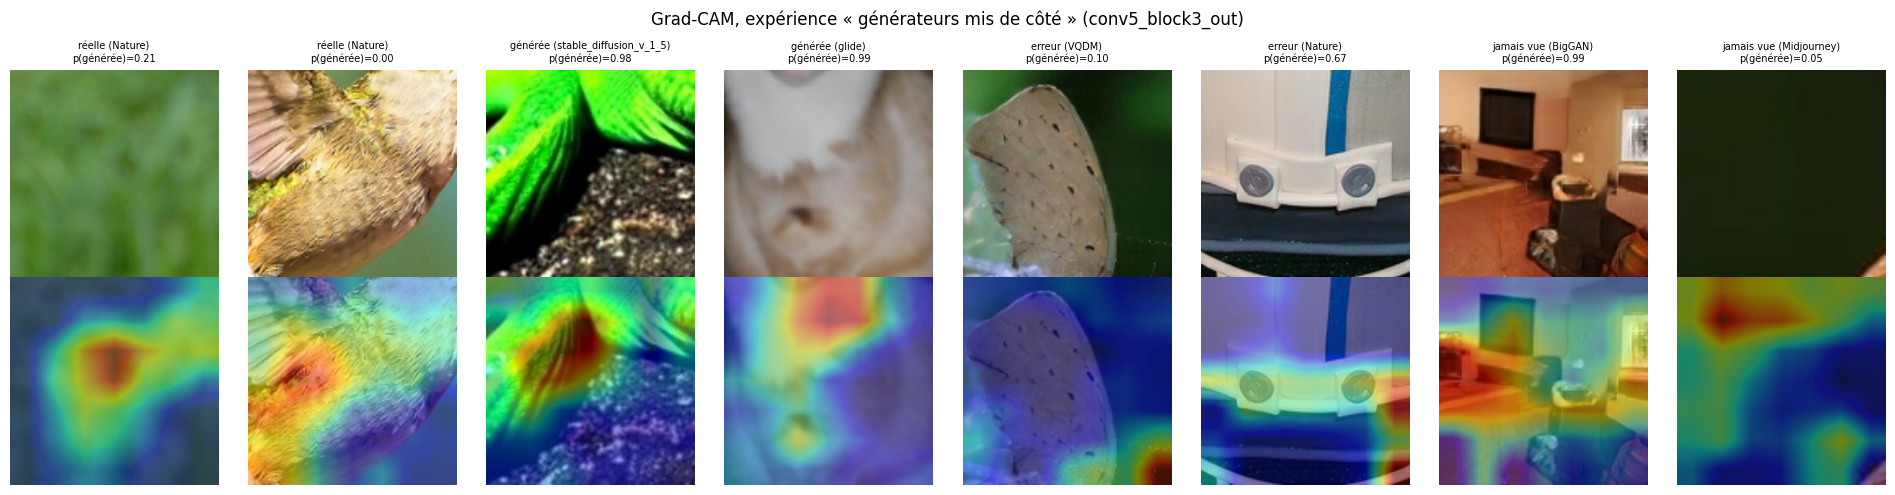

In [11]:
def gradcam_heatmap(model, image):
    """Computes the Grad-CAM map of an image for the predicted class.

    Args:
        model: trained model (ResNet50 + head).
        image: preprocessed image, tensor (INPUT_SIZE, INPUT_SIZE, 3).

    Returns:
        (NumPy heatmap between 0 and 1, “generated” probability) pair.
    """
    backbone = model.get_layer("resnet50")
    head = model.layers[model.layers.index(backbone) + 1:]  # GAP, Dropout, Dense
    with tf.GradientTape() as tape:
        feature_maps = tf.cast(backbone(image[None], training=False), tf.float32)  # output of conv5_block3_out
        tape.watch(feature_maps)
        output = feature_maps
        for layer in head:
            output = layer(output, training=False)
        probability = output[0, 0]
        # We explain the predicted class: “generated” if p >= threshold, otherwise “real”
        score = probability if probability >= THRESHOLD else 1 - probability
    gradients = tape.gradient(score, feature_maps)
    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))  # importance of each channel
    heatmap = tf.nn.relu(tf.reduce_sum(feature_maps[0] * channel_weights, axis=-1))
    heatmap /= tf.reduce_max(heatmap) + 1e-8
    return heatmap.numpy(), float(probability)


def pick_gradcam_examples(test_df, test_probabilities, held_df, held_probabilities, seed):
    """Picks the 8 examples: 2 real, 2 correctly classified generated, 2 errors, 2 never seen.

    Args:
        test_df: test set of the “held-out generators” experiment.
        test_probabilities: probabilities predicted on this set.
        held_df: test set of the held-out generators.
        held_probabilities: probabilities predicted on this set.
        seed: sampling seed.

    Returns:
        List of (title, image path) pairs.
    """
    test = test_df.assign(correct=(test_probabilities >= THRESHOLD).astype(int) == test_df["label"].values)
    held = held_df.assign(correct=(held_probabilities >= THRESHOLD).astype(int) == held_df["label"].values)
    groups = [
        ("real", test[(test["label"] == 0) & test["correct"]]),
        ("generated", test[(test["label"] == 1) & test["correct"]]),
        ("error", test[~test["correct"]]),
        ("never seen", held[held["source"].isin(HELD_OUT_GENERATORS)]),
    ]
    examples = []
    for kind, group in groups:
        for _, row in group.sample(min(2, len(group)), random_state=seed).iterrows():
            examples.append((f"{kind} ({row['source']})", row["path"]))
    return examples


def show_gradcam(model, examples):
    """Shows each example with its Grad-CAM map overlaid.

    Args:
        model: trained model.
        examples: list of (title, image path) pairs.
    """
    fig, axes = plt.subplots(2, len(examples), figsize=(2.4 * len(examples), 5))
    for col, (title, path) in enumerate(examples):
        display_image = load_display_image(path)
        model_input = keras.applications.resnet50.preprocess_input(display_image.astype("float32"))
        heatmap, probability = gradcam_heatmap(model, tf.constant(model_input))
        heatmap = tf.image.resize(heatmap[..., None], [INPUT_SIZE, INPUT_SIZE]).numpy()[..., 0]  # 7×7 -> 224×224
        axes[0, col].imshow(display_image)
        axes[0, col].set_title(f"{title}\np(generated)={probability:.2f}", fontsize=7)
        axes[1, col].imshow(display_image)
        axes[1, col].imshow(heatmap, cmap="jet", alpha=0.45)
        for row in range(2):
            axes[row, col].axis("off")
    fig.suptitle("Grad-CAM, “held-out generators” experiment (conv5_block3_out)")
    plt.tight_layout()
    plt.show()


name_test = "“held-out generators” → test"
name_held = "“held-out generators” → Midjourney + BigGAN"
gradcam_examples = pick_gradcam_examples(
    splits_held_out["test"], probabilities_by_eval[name_test],
    held_out_test, probabilities_by_eval[name_held], SEED,
)
show_gradcam(model_held_out, gradcam_examples)

## 12. Conclusion and limitations

Results of training run 2 on Kaggle (1 T4 GPU), compared with training run 1 (no augmentation).

**Results**
- **Standard tests**: accuracy 0.929 / AUC 0.981 (“all generators”) and 0.936 / 0.984 (“held-out generators”) with 1 crop; 0.945 / 0.987 and 0.947 / 0.991 with the 3 × 3 grid. Run 1 reached 0.95 / 0.99: the augmentation costs about 2 points on clean images.
- **Never-seen generators** (1 crop): BigGAN detected at 93.8%, Midjourney at 84.9% (run 1: 94.9% and 88.2%). The model generalises to a GAN and to a commercial generator after training only on diffusion models.

**Anti-shortcut checks**
- **Scores per source**: no generator at 100%, no suspicious gap. VQDM remains the hardest known generator (~87%).
- **Perturbation test**: under JPEG 75 or blur σ = 1, the share of real photos classified “generated” drops from about 40% (run 1) to about 15%. JPEG 40 (13–15%) and the never-seen downscale (21–22%) are handled reasonably well. **Blur σ = 2.5 still flips about half of the real photos**: the robustness does not extend beyond the augmentation range (σ ≤ 2).

**Grad-CAM**: correct answers rely on textured, structured areas (feathers, scales, subject edges). A nearly entirely blurred real photo is now correctly classified “real”. Remaining errors: very smooth manufactured surfaces, and Midjourney crops that are almost uniformly dark.

**Multi-crop evaluation**: the 3 × 3 grid improves the standard tests, but it drops never-seen Midjourney from 84.9% to 59.6% while its AUC stays at 0.98. Averaging dilutes the signal when the border crops land on smooth backgrounds: the 0.5 threshold no longer fits, the ranking is still good.

**Limitations**
- Content limited to ImageNet categories (mostly animals and objects).
- A 128 px crop sees only a small part of large images (1/64 of a Midjourney image).
- A single run per experiment, no hyperparameter search; about 125 test images per generator (one image = 0.8 point).
- Generators dating from 2023 or earlier.

**Future work**
- Without retraining: aggregate the grid with the maximum (or top-3) instead of the mean, choose the threshold on the validation set, report the AUC per generator.
- With retraining: blur up to σ = 3 and downscale-upscale as augmentation, other backbones (EfficientNet, ConvNeXt), a test set with more varied content and recent generators (Extended Synthbuster).